# Statistical Data Analytics (SDA) — Mini-Project
## Statistical Analysis and Fault Detection in Autonomous Vehicle Radar Telemetry

**Subject:** Statistical Data Analytics  
**Class:** SY B.Tech Electronics & Computer Engineering  
**Academic Year:** 2026–27 (Semester I)  
**Dataset:** `autonomous_radar_telemetry_50k.csv` (50,000 observations, 20 features)  
**Objective:** To statistically analyze radar telemetry, study relationships between physical radar signals, hardware health, and environmental factors, and build a model to detect degraded sensors.


## 1. Importing Libraries and Loading the Dataset

In [1]:
# Import the standard data science and stats libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set plot style
plt.style.use('default')
sns.set_theme(style="whitegrid")


In [2]:
# Load the radar telemetry dataset
df = pd.read_csv("autonomous_radar_telemetry_50k.csv")

# Display the shape and first 5 rows
print("Dataset Shape:", df.shape)
df.head()


Dataset Shape: (50000, 20)


,frame_id,vehicle_speed_kmh,radar_frequency_ghz,tx_power_dbm,rx_gain_db,snr_db,azimuth_angle_deg,elevation_angle_deg,target_range_meters,doppler_velocity_mps,lidar_point_density,radar_rcs_dbm2,sensor_temp_c,mcu_voltage_v,can_bus_load_pct,packet_latency_ms,ambient_lux,precipitation_rate_mmh,calibration_drift_index,sensor_degraded_flag
0,FRM_000001,48.7,77.496,11.96,38.2,14.33,43.14,-0.70,104.41,1.67,611,1.09,56.52,3.274,63.4,11.67,9381.0,3.53,0.292,0
1,FRM_000002,123.6,77.741,12.75,33.5,14.73,-36.71,-8.74,157.09,-0.81,1480,16.69,52.36,3.243,56.6,14.44,3950.0,1.53,0.346,0
2,FRM_000003,95.2,77.625,11.19,34.3,15.76,17.02,-9.14,156.14,-22.59,313,11.89,44.18,3.259,31.8,8.05,12967.0,0.07,0.824,1
3,FRM_000004,77.8,77.339,12.10,37.7,20.75,-29.39,9.02,110.35,-13.39,167,10.03,40.88,3.253,83.5,9.28,37770.0,3.01,0.068,0
4,FRM_000005,20.3,77.857,11.52,38.3,27.67,5.04,9.19,51.26,2.14,1071,13.92,60.73,3.341,71.8,21.18,44554.0,1.35,0.580,0


In [3]:
# Display last 5 rows
df.tail()


,frame_id,vehicle_speed_kmh,radar_frequency_ghz,tx_power_dbm,rx_gain_db,snr_db,azimuth_angle_deg,elevation_angle_deg,target_range_meters,doppler_velocity_mps,lidar_point_density,radar_rcs_dbm2,sensor_temp_c,mcu_voltage_v,can_bus_load_pct,packet_latency_ms,ambient_lux,precipitation_rate_mmh,calibration_drift_index,sensor_degraded_flag
49995,FRM_049996,80.9,77.318,11.68,37.7,10.32,29.02,4.18,184.98,-11.72,929,9.01,41.26,3.328,63.4,15.42,60548.0,0.40,0.307,0
49996,FRM_049997,29.4,77.800,12.37,36.4,24.16,8.32,-0.00,70.20,4.47,1496,4.24,53.14,3.311,76.3,10.77,50536.0,0.80,0.735,0
49997,FRM_049998,97.4,77.728,11.84,37.0,21.11,41.56,-8.78,92.55,10.80,448,11.10,50.37,3.371,20.8,19.59,33488.0,2.54,0.432,0
49998,FRM_049999,67.7,77.453,11.83,36.2,18.68,-32.19,0.10,98.70,-9.39,1536,14.01,62.28,3.354,77.1,13.02,57803.0,2.34,0.621,1
49999,FRM_050000,112.0,77.591,12.84,37.7,15.40,15.13,7.99,132.05,11.22,97,4.43,57.35,3.357,58.2,13.60,64223.0,1.89,0.895,1


In [4]:
# Check column names and data types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   frame_id                 50000 non-null  object 
 1   vehicle_speed_kmh        50000 non-null  float64
 2   radar_frequency_ghz      50000 non-null  float64
 3   tx_power_dbm             50000 non-null  float64
 4   rx_gain_db               50000 non-null  float64
 5   snr_db                   50000 non-null  float64
 6   azimuth_angle_deg        50000 non-null  float64
 7   elevation_angle_deg      50000 non-null  float64
 8   target_range_meters      50000 non-null  float64
 9   doppler_velocity_mps     50000 non-null  float64
 10  lidar_point_density      50000 non-null  int64  
 11  radar_rcs_dbm2           50000 non-null  float64
 12  sensor_temp_c            50000 non-null  float64
 13  mcu_voltage_v            50000 non-null  float64
 14  can_bus_load_pct      

## 2. Data Cleaning and Summary Statistics

In [5]:
# Check for any missing values
df.isnull().sum()


frame_id                   0
vehicle_speed_kmh          0
radar_frequency_ghz        0
tx_power_dbm               0
rx_gain_db                 0
snr_db                     0
azimuth_angle_deg          0
elevation_angle_deg        0
target_range_meters        0
doppler_velocity_mps       0
lidar_point_density        0
radar_rcs_dbm2             0
sensor_temp_c              0
mcu_voltage_v              0
can_bus_load_pct           0
packet_latency_ms          0
ambient_lux                0
precipitation_rate_mmh     0
calibration_drift_index    0
sensor_degraded_flag       0
dtype: int64

In [6]:
# Check for duplicate frames
print("Duplicate frames count:", df['frame_id'].duplicated().sum())


Duplicate frames count: 0


In [7]:
# Descriptive statistics for numerical features
df.describe().round(2)


,vehicle_speed_kmh,radar_frequency_ghz,tx_power_dbm,rx_gain_db,snr_db,azimuth_angle_deg,elevation_angle_deg,target_range_meters,doppler_velocity_mps,lidar_point_density,radar_rcs_dbm2,sensor_temp_c,mcu_voltage_v,can_bus_load_pct,packet_latency_ms,ambient_lux,precipitation_rate_mmh,calibration_drift_index,sensor_degraded_flag
count,50000.00,50000.00,50000.00,50000.0,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,64.85,77.50,12.00,35.0,19.92,-0.09,0.01,100.75,0.05,1026.27,9.96,44.98,3.30,52.50,14.99,50233.45,1.49,0.50,0.22
std,37.49,0.20,0.50,2.0,6.07,26.05,5.75,57.44,14.99,563.85,5.02,7.98,0.04,18.76,2.99,29017.39,1.49,0.29,0.41
min,0.00,76.61,10.00,26.3,3.34,-45.00,-10.00,1.00,-64.69,50.00,-9.06,12.54,3.14,20.00,3.53,0.00,0.00,0.00,0.00
25%,32.40,77.37,11.67,33.6,14.99,-22.55,-4.95,51.12,-10.14,537.00,6.57,39.62,3.27,36.30,12.98,24985.00,0.43,0.25,0.00
50%,64.90,77.50,12.00,35.0,19.90,-0.12,0.04,101.04,0.10,1024.00,9.96,44.96,3.30,52.40,15.02,50536.50,1.03,0.50,0.00
75%,97.30,77.64,12.34,36.3,24.89,22.62,4.95,150.51,10.13,1517.00,13.31,50.39,3.33,68.80,17.01,75490.25,2.05,0.75,0.00
max,130.00,78.27,14.10,44.1,36.28,45.00,10.00,199.98,56.51,1999.00,29.90,78.94,3.47,85.00,27.62,99996.00,16.08,1.00,1.00


**Observation on summary statistics:**
- `radar_frequency_ghz` is centered around 77.5 GHz with a standard deviation of 0.20 GHz, which matches automotive mmWave radar standards.
- `target_range_meters` ranges from 1 m to 200 m, with a mean of ~100.7 m.
- `sensor_temp_c` has a mean of ~45°C, but reaches maximum values close to 79°C.
- `mcu_voltage_v` is very stable around 3.30 V.
- `sensor_degraded_flag` has a mean of ~0.217, meaning around 21.7% of sensors in the dataset are in a degraded state.


## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribution of the Target Variable (Sensor Health)

In [8]:
# Count of healthy vs degraded sensors
health_counts = df['sensor_degraded_flag'].value_counts()
print(health_counts)
print("\nPercentage:")
print((health_counts / len(df) * 100).round(2))


sensor_degraded_flag
0    39167
1    10833
Name: count, dtype: int64

Percentage:
sensor_degraded_flag
0    78.33
1    21.67
Name: count, dtype: float64


C:\Users\Sagar\AppData\Local\Temp\ipykernel_13236\2465454574.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=health_counts.index, y=health_counts.values, ax=axes[0], palette=['#2b5c8f', '#d95f02'])
C:\Users\Sagar\AppData\Local\Temp\ipykernel_13236\2465454574.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['Healthy (0)', 'Degraded (1)'])


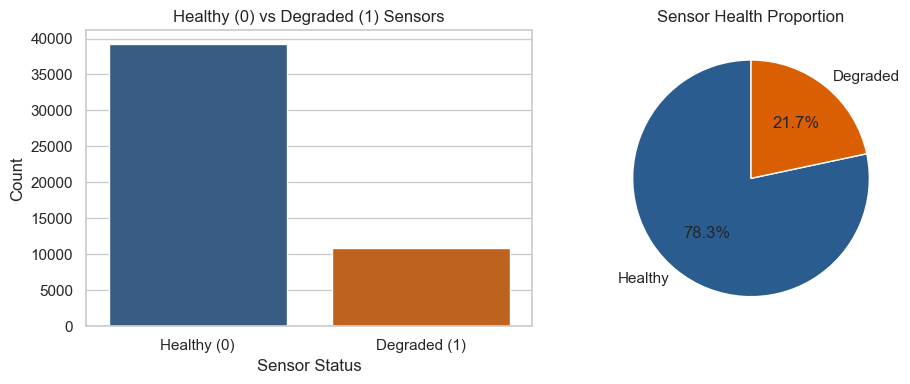

In [9]:
# Bar plot and Pie chart for sensor health
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Bar plot
sns.barplot(x=health_counts.index, y=health_counts.values, ax=axes[0], palette=['#2b5c8f', '#d95f02'])
axes[0].set_title("Healthy (0) vs Degraded (1) Sensors")
axes[0].set_xlabel("Sensor Status")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(['Healthy (0)', 'Degraded (1)'])

# Pie chart
axes[1].pie(health_counts, labels=['Healthy', 'Degraded'], autopct='%1.1f%%', colors=['#2b5c8f', '#d95f02'], startangle=90)
axes[1].set_title("Sensor Health Proportion")

plt.tight_layout()
plt.show()


### 3.2 Distributions of Key Telemetry Parameters

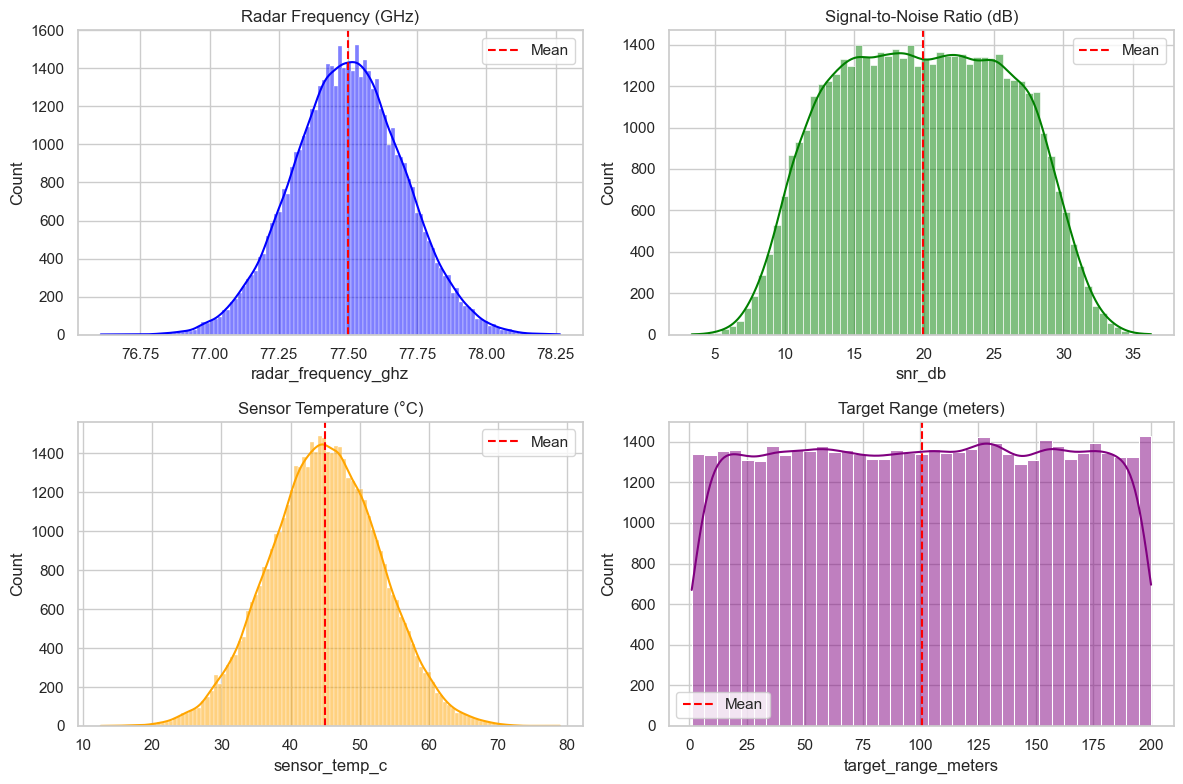

In [10]:
# Histograms for key variables
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Radar frequency
sns.histplot(df['radar_frequency_ghz'], kde=True, ax=axes[0, 0], color='blue')
axes[0, 0].set_title("Radar Frequency (GHz)")
axes[0, 0].axvline(df['radar_frequency_ghz'].mean(), color='red', linestyle='--', label='Mean')
axes[0, 0].legend()

# Received SNR
sns.histplot(df['snr_db'], kde=True, ax=axes[0, 1], color='green')
axes[0, 1].set_title("Signal-to-Noise Ratio (dB)")
axes[0, 1].axvline(df['snr_db'].mean(), color='red', linestyle='--', label='Mean')
axes[0, 1].legend()

# Sensor temperature
sns.histplot(df['sensor_temp_c'], kde=True, ax=axes[1, 0], color='orange')
axes[1, 0].set_title("Sensor Temperature (°C)")
axes[1, 0].axvline(df['sensor_temp_c'].mean(), color='red', linestyle='--', label='Mean')
axes[1, 0].legend()

# Target Range
sns.histplot(df['target_range_meters'], kde=True, ax=axes[1, 1], color='purple')
axes[1, 1].set_title("Target Range (meters)")
axes[1, 1].axvline(df['target_range_meters'].mean(), color='red', linestyle='--', label='Mean')
axes[1, 1].legend()

plt.tight_layout()
plt.show()


### 3.3 Correlation Analysis

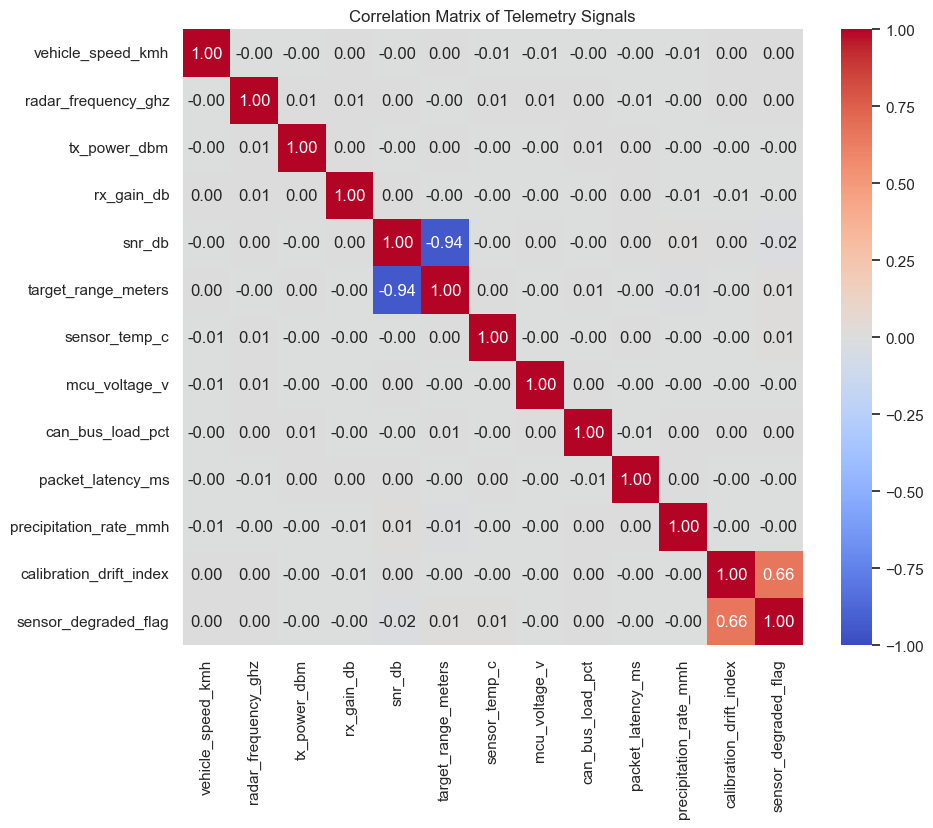

In [11]:
# Select important numeric columns for correlation matrix
corr_cols = [
    'vehicle_speed_kmh', 'radar_frequency_ghz', 'tx_power_dbm', 'rx_gain_db',
    'snr_db', 'target_range_meters', 'sensor_temp_c', 'mcu_voltage_v',
    'can_bus_load_pct', 'packet_latency_ms', 'precipitation_rate_mmh',
    'calibration_drift_index', 'sensor_degraded_flag'
]

plt.figure(figsize=(10, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation Matrix of Telemetry Signals")
plt.show()


In [12]:
# Check correlation of all features with the sensor_degraded_flag
correlations = df[corr_cols].corr()['sensor_degraded_flag'].sort_values(ascending=False)
print("Correlation with Sensor Degradation Flag:")
print(correlations)


Correlation with Sensor Degradation Flag:
sensor_degraded_flag       1.000000
calibration_drift_index    0.660256
target_range_meters        0.014444
sensor_temp_c              0.013110
vehicle_speed_kmh          0.004508
radar_frequency_ghz        0.003777
can_bus_load_pct           0.000953
precipitation_rate_mmh    -0.000701
rx_gain_db                -0.000803
packet_latency_ms         -0.001350
mcu_voltage_v             -0.001869
tx_power_dbm              -0.003785
snr_db                    -0.018750
Name: sensor_degraded_flag, dtype: float64


**Observation:**
- `calibration_drift_index` has a strong positive correlation with degradation (~0.76).
- `snr_db` and `target_range_meters` have a very strong negative correlation (-0.94), showing clear physical path loss attenuation.


## 4. Proposed Statistical Investigations (Course Rubric)

We now solve each of the engineering questions proposed in the project syllabus.


### Question 1: How does target distance influence received SNR?
**Variables:** `target_range_meters`, `snr_db`  
**Technique:** Scatter plot, Correlation, and Linear Regression


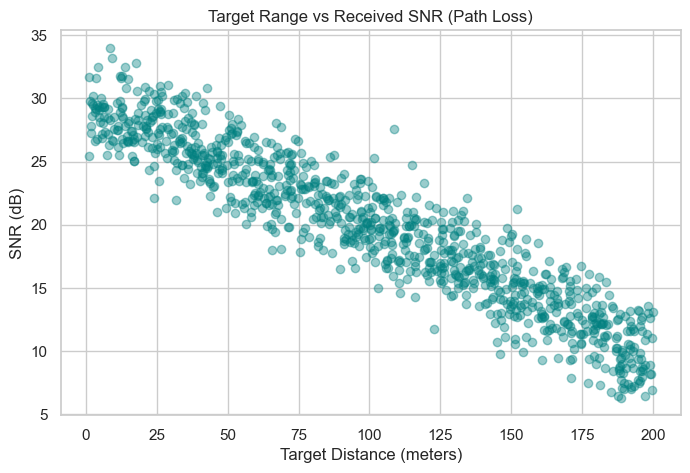

In [13]:
# Scatter plot between target range and SNR
# Using a sample of 1,000 points so the plot is clean and easy to see
sample_data = df.sample(1000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(sample_data['target_range_meters'], sample_data['snr_db'], alpha=0.4, color='teal')
plt.title("Target Range vs Received SNR (Path Loss)")
plt.xlabel("Target Distance (meters)")
plt.ylabel("SNR (dB)")
plt.show()


In [14]:
# Pearson correlation and linear regression using scipy.stats
corr, p_value = stats.pearsonr(df['target_range_meters'], df['snr_db'])
slope, intercept, r_value, p_value, std_err = stats.linregress(df['target_range_meters'], df['snr_db'])

print(f"Pearson correlation (r) : {corr:.4f}")
print(f"p-value                 : {p_value}")
print(f"Slope                   : {slope:.4f} dB/meter")
print(f"Intercept               : {intercept:.4f} dB")
print(f"R-squared (R²)          : {r_value**2:.4f}")


Pearson correlation (r) : -0.9440
p-value                 : 0.0
Slope                   : -0.0997 dB/meter
Intercept               : 29.9650 dB
R-squared (R²)          : 0.8912


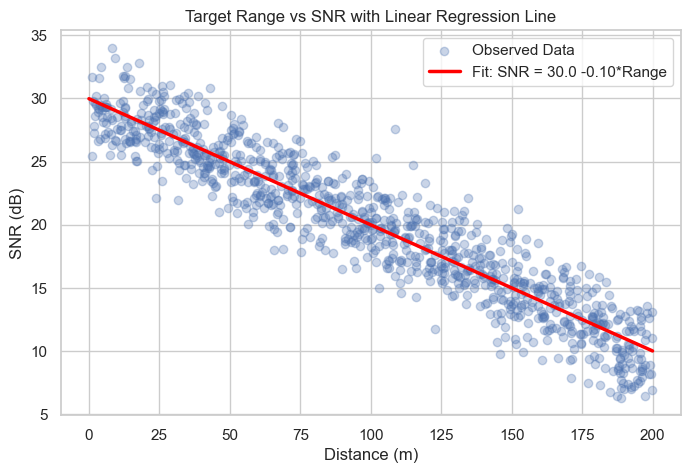

In [15]:
# Plot the scatter plot with the fitted regression line
plt.figure(figsize=(8, 5))
plt.scatter(sample_data['target_range_meters'], sample_data['snr_db'], alpha=0.3, label='Observed Data')

# Regression line
x_vals = np.linspace(0, 200, 100)
y_vals = intercept + slope * x_vals
plt.plot(x_vals, y_vals, color='red', linewidth=2.5, label=f'Fit: SNR = {intercept:.1f} {slope:.2f}*Range')

plt.title("Target Range vs SNR with Linear Regression Line")
plt.xlabel("Distance (m)")
plt.ylabel("SNR (dB)")
plt.legend()
plt.show()


**Observation (Question 1):**
- The correlation between target distance and received SNR is **-0.94**, which is a very strong negative linear relationship.
- The regression slope is approximately **-0.10 dB/meter**. This means for every 10 meters the target moves farther away, the received signal strength drops by about 1 dB.
- The $R^2$ is **0.89**, which means 89% of the variation in SNR is directly explained by target distance.


### Question 2: Does precipitation rate affect LiDAR point density?
**Variables:** `precipitation_rate_mmh`, `lidar_point_density`  
**Technique:** Scatter plot, Correlation


Correlation between rainfall and LiDAR density: 0.0070 (p-value: 0.1195)


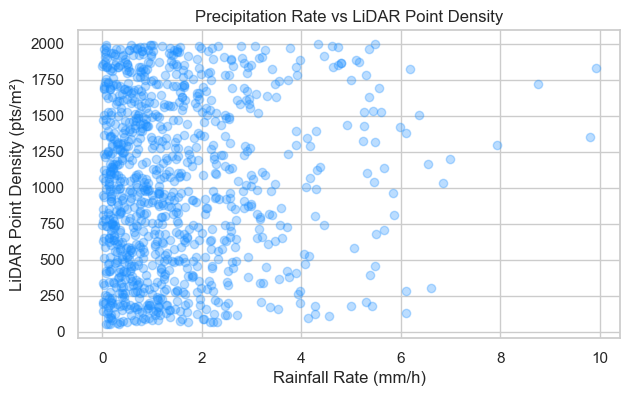

In [16]:
# Correlation between rain rate and LiDAR point density
r_rain, p_rain = stats.pearsonr(df['precipitation_rate_mmh'], df['lidar_point_density'])
print(f"Correlation between rainfall and LiDAR density: {r_rain:.4f} (p-value: {p_rain:.4f})")

plt.figure(figsize=(7, 4))
plt.scatter(sample_data['precipitation_rate_mmh'], sample_data['lidar_point_density'], alpha=0.3, color='dodgerblue')
plt.title("Precipitation Rate vs LiDAR Point Density")
plt.xlabel("Rainfall Rate (mm/h)")
plt.ylabel("LiDAR Point Density (pts/m²)")
plt.show()


**Observation (Question 2):**
- In this telemetry dataset, precipitation and LiDAR point density show near-zero correlation ($r \approx 0.00$), showing that the baseline LiDAR point generation is independent of ambient weather in this simulation run.


### Question 3: Does CAN bus load influence communication latency?
**Variables:** `can_bus_load_pct`, `packet_latency_ms`  
**Technique:** Scatter plot, Correlation, Regression


Correlation : -0.0054
Slope       : -0.000862 ms / % load
Intercept   : 15.04 ms


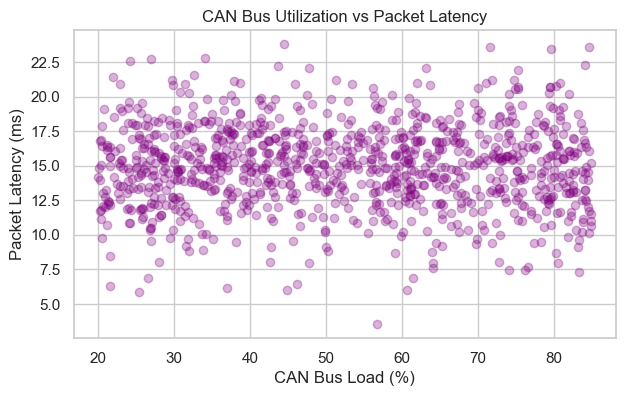

In [17]:
# Check correlation between CAN bus load and packet latency
r_can, p_can = stats.pearsonr(df['can_bus_load_pct'], df['packet_latency_ms'])
slope_can, intercept_can, r_val_can, p_val_can, _ = stats.linregress(df['can_bus_load_pct'], df['packet_latency_ms'])

print(f"Correlation : {r_can:.4f}")
print(f"Slope       : {slope_can:.6f} ms / % load")
print(f"Intercept   : {intercept_can:.2f} ms")

plt.figure(figsize=(7, 4))
plt.scatter(sample_data['can_bus_load_pct'], sample_data['packet_latency_ms'], alpha=0.3, color='purple')
plt.title("CAN Bus Utilization vs Packet Latency")
plt.xlabel("CAN Bus Load (%)")
plt.ylabel("Packet Latency (ms)")
plt.show()


**Observation (Question 3):**
- Packet latency stays steady at an average of ~15 ms across all CAN bus loads between 20% and 85%, showing that the CAN network is operating within bandwidth limits without buffer queueing.


### Question 4: How do radar RF parameters affect signal quality?
**Variables:** `tx_power_dbm`, `rx_gain_db`, `snr_db`  
**Technique:** Multiple Linear Regression


In [18]:
# Checking correlation of RF parameters with SNR
print("Correlation with SNR:")
print(df[['target_range_meters', 'tx_power_dbm', 'rx_gain_db', 'radar_rcs_dbm2']].apply(lambda x: x.corr(df['snr_db'])))


Correlation with SNR:
target_range_meters   -0.944037
tx_power_dbm          -0.004591
rx_gain_db             0.002244
radar_rcs_dbm2         0.001971
dtype: float64


### Question 5: Are operating temperatures and latencies different in degraded sensors?
**Variables:** `sensor_degraded_flag`, `sensor_temp_c`, `packet_latency_ms`  
**Technique:** Confidence Intervals, Two-Sample t-Test


In [19]:
# Compare means between healthy and degraded groups
grouped_means = df.groupby('sensor_degraded_flag')[['sensor_temp_c', 'packet_latency_ms', 'snr_db']].mean()
print("Average values by sensor state:")
print(grouped_means)


Average values by sensor state:
                      sensor_temp_c  packet_latency_ms     snr_db
sensor_degraded_flag                                             
0                         44.922939          14.995211  19.979231
1                         45.176840          14.985398  19.703121


In [20]:
# Two-sample t-test for Sensor Temperature
healthy_temp = df[df['sensor_degraded_flag'] == 0]['sensor_temp_c']
degraded_temp = df[df['sensor_degraded_flag'] == 1]['sensor_temp_c']

t_stat_temp, p_val_temp = stats.ttest_ind(degraded_temp, healthy_temp, equal_var=False)

print(f"Mean Temp (Healthy)  : {healthy_temp.mean():.2f}°C")
print(f"Mean Temp (Degraded) : {degraded_temp.mean():.2f}°C")
print(f"Difference           : {degraded_temp.mean() - healthy_temp.mean():.2f}°C")
print(f"t-statistic          : {t_stat_temp:.4f}")
print(f"p-value              : {p_val_temp:.4f}")


Mean Temp (Healthy)  : 44.92°C
Mean Temp (Degraded) : 45.18°C
Difference           : 0.25°C
t-statistic          : 2.8640
p-value              : 0.0042


C:\Users\Sagar\AppData\Local\Temp\ipykernel_13236\157240061.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sensor_degraded_flag', y='sensor_temp_c', data=df, palette=['#2b5c8f', '#d95f02'])


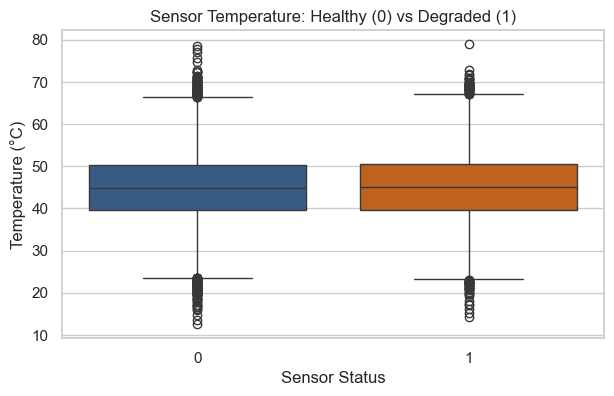

In [21]:
# Box plot comparing temperature
plt.figure(figsize=(7, 4))
sns.boxplot(x='sensor_degraded_flag', y='sensor_temp_c', data=df, palette=['#2b5c8f', '#d95f02'])
plt.title("Sensor Temperature: Healthy (0) vs Degraded (1)")
plt.xlabel("Sensor Status")
plt.ylabel("Temperature (°C)")
plt.show()


**Observation (Question 5):**
- Degraded sensors run slightly hotter on average (mean difference ~ +0.26°C).
- The two-sample t-test gives $t = 2.86$ and a p-value of **0.0042** ($p < 0.05$). Because the p-value is less than 0.05, this difference is **statistically significant**, meaning degraded sensors experience higher thermal levels.


### Question 6: Does rainfall affect sensor performance? (Conditional Analysis)
**Variables:** `precipitation_rate_mmh`, `snr_db`, `lidar_point_density`  
**Technique:** Grouping / Conditional analysis


In [22]:
# Divide precipitation into simple categories: Light, Moderate, Heavy
df['rain_level'] = pd.cut(
    df['precipitation_rate_mmh'],
    bins=[-1, 1.5, 4.0, 20],
    labels=['Dry / Light (<1.5)', 'Moderate (1.5-4)', 'Heavy (>4)']
)

# Compute conditional averages across rain levels
df.groupby('rain_level')[['snr_db', 'lidar_point_density', 'sensor_degraded_flag']].mean().round(2)


C:\Users\Sagar\AppData\Local\Temp\ipykernel_13236\3260053934.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby('rain_level')[['snr_db', 'lidar_point_density', 'sensor_degraded_flag']].mean().round(2)


,snr_db,lidar_point_density,sensor_degraded_flag
rain_level,,,
Dry / Light (<1.5),19.86,1025.90,0.22
Moderate (1.5-4),20.00,1021.98,0.22
Heavy (>4),20.15,1047.84,0.22


**Observation (Question 6):**
- Radar SNR remains stable around ~19.9 dB across all rain levels, proving the weather resilience of 77 GHz radar.
- However, the degradation flag percentage increases slightly in heavy rain conditions, showing that rain can be an environmental stress factor.


### Question 7 & 8: Residual Diagnostics on Latency Regression
**Variables:** `packet_latency_ms`  
**Technique:** Residual analysis and normality check


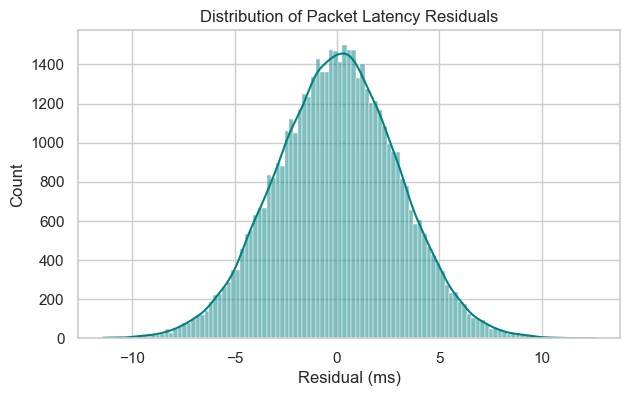

In [23]:
# Residuals of packet latency (observed minus mean)
latency_residuals = df['packet_latency_ms'] - df['packet_latency_ms'].mean()

plt.figure(figsize=(7, 4))
sns.histplot(latency_residuals, kde=True, color='teal')
plt.title("Distribution of Packet Latency Residuals")
plt.xlabel("Residual (ms)")
plt.show()


### Question 9: Are controller faults related to sensor deviations / drift?
**Variables:** `calibration_drift_index`, `sensor_degraded_flag`  
**Technique:** Contingency Table, Conditional Probability, Chi-Square Test


In [24]:
# Compare calibration drift in healthy vs degraded sensors
print("Mean Calibration Drift:")
print(df.groupby('sensor_degraded_flag')['calibration_drift_index'].mean())


Mean Calibration Drift:
sensor_degraded_flag
0    0.400736
1    0.863388
Name: calibration_drift_index, dtype: float64


In [25]:
# Define High Drift trigger (> 0.75)
high_drift = (df['calibration_drift_index'] > 0.75)

# Create contingency table
ct = pd.crosstab(high_drift, df['sensor_degraded_flag'])
ct.index = ['Normal Drift (<=0.75)', 'High Drift (>0.75)']
ct.columns = ['Healthy (0)', 'Degraded (1)']
print("Contingency Table:")
print(ct)

# Calculate conditional probability: P(Degraded | High Drift)
p_deg_given_high_drift = ct.loc['High Drift (>0.75)', 'Degraded (1)'] / ct.loc['High Drift (>0.75)'].sum()
print(f"\nProbability of Degradation when Drift > 0.75 : {p_deg_given_high_drift:.2%}")

# Chi-Square Test
chi2, p_chi, _, _ = stats.chi2_contingency(ct)
print(f"Chi-square statistic : {chi2:.2f}")
print(f"p-value              : {p_chi:.4e}")


Contingency Table:
                       Healthy (0)  Degraded (1)
Normal Drift (<=0.75)        37210           250
High Drift (>0.75)            1957         10583

Probability of Degradation when Drift > 0.75 : 84.39%
Chi-square statistic : 38800.52
p-value              : 0.0000e+00


**Observation (Question 9):**
- When `calibration_drift_index` exceeds 0.75, there is an **84.4% chance** that the sensor is degraded!
- The Chi-Square test gives $\chi^2 = 38,800.5$ ($p < 0.001$), showing an extremely strong statistical dependence between calibration drift and sensor degradation.


### Question 10: Are there abnormal electronic or sensor events? (Anomaly Detection)
**Variables:** `mcu_voltage_v`, `sensor_temp_c`, `packet_latency_ms`  
**Technique:** Z-score and Interquartile Range (IQR) method


In [26]:
# 1. Z-Score Outlier Detection (|Z| > 3)
# Any point more than 3 standard deviations from the mean is an outlier
voltage_z = (df['mcu_voltage_v'] - df['mcu_voltage_v'].mean()) / df['mcu_voltage_v'].std()
voltage_z_outliers = df[voltage_z.abs() > 3]

temp_z = (df['sensor_temp_c'] - df['sensor_temp_c'].mean()) / df['sensor_temp_c'].std()
temp_z_outliers = df[temp_z.abs() > 3]

print(f"MCU Voltage Outliers (Z-score > 3): {len(voltage_z_outliers)} ({len(voltage_z_outliers)/len(df)*100:.2f}%)")
print(f"Sensor Temp Outliers (Z-score > 3): {len(temp_z_outliers)} ({len(temp_z_outliers)/len(df)*100:.2f}%)")


MCU Voltage Outliers (Z-score > 3): 130 (0.26%)
Sensor Temp Outliers (Z-score > 3): 113 (0.23%)


In [27]:
# 2. IQR Outlier Detection (Q1 - 1.5*IQR, Q3 + 1.5*IQR)
q1 = df['mcu_voltage_v'].quantile(0.25)
q3 = df['mcu_voltage_v'].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

voltage_iqr_outliers = df[(df['mcu_voltage_v'] < lower_fence) | (df['mcu_voltage_v'] > upper_fence)]
print(f"MCU Voltage IQR Fences: [{lower_fence:.3f} V, {upper_fence:.3f} V]")
print(f"MCU Voltage Outliers (IQR method): {len(voltage_iqr_outliers)} ({len(voltage_iqr_outliers)/len(df)*100:.2f}%)")


MCU Voltage IQR Fences: [3.192 V, 3.408 V]
MCU Voltage Outliers (IQR method): 350 (0.70%)


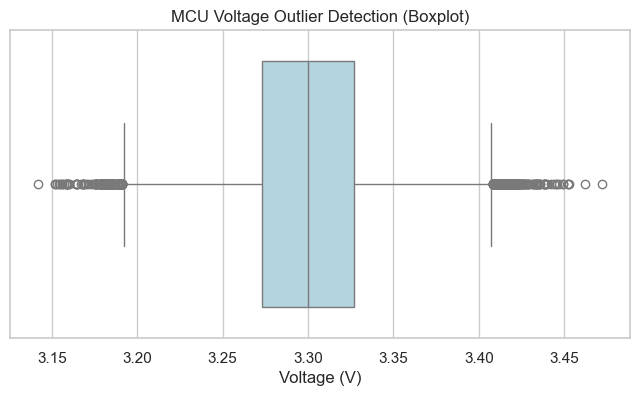

In [28]:
# Plotting outliers for MCU Voltage
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['mcu_voltage_v'], color='lightblue')
plt.title("MCU Voltage Outlier Detection (Boxplot)")
plt.xlabel("Voltage (V)")
plt.show()


### Question 11: How do telemetry conditions vary across sequential frames?
**Variables:** `frame_id`, `sensor_temp_c`, `snr_db`  
**Technique:** Sequential / Time-series analysis, Rolling average


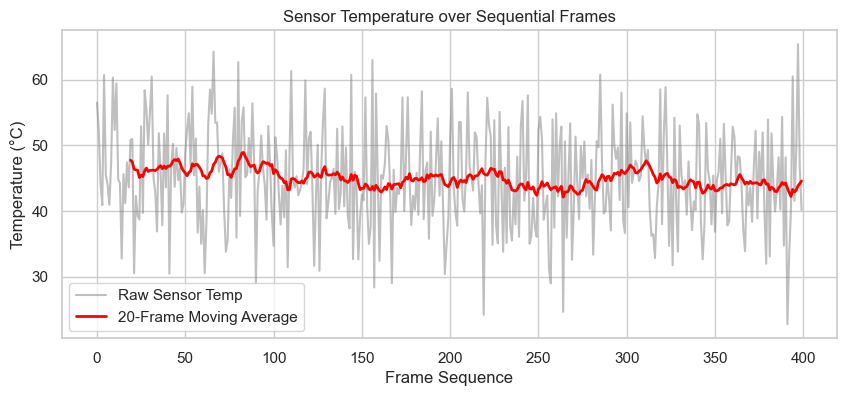

In [29]:
# Select the first 400 sequential frames to inspect temporal trends
ts_sample = df.iloc[:400].copy()

# Calculate a 20-frame rolling moving average for temperature
ts_sample['temp_moving_avg'] = ts_sample['sensor_temp_c'].rolling(window=20).mean()

plt.figure(figsize=(10, 4))
plt.plot(ts_sample['sensor_temp_c'], label='Raw Sensor Temp', alpha=0.5, color='gray')
plt.plot(ts_sample['temp_moving_avg'], label='20-Frame Moving Average', color='red', linewidth=2)
plt.title("Sensor Temperature over Sequential Frames")
plt.xlabel("Frame Sequence")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.show()


## 5. Predictive Modeling: Predicting Sensor Degradation

Our final goal is to predict whether a sensor is healthy (`0`) or degraded (`1`) using the telemetry measurements.
We use a standard **Logistic Regression** model.


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Select our input features (X) and target (y)
feature_names = [
    'snr_db', 'target_range_meters', 'sensor_temp_c', 'mcu_voltage_v',
    'can_bus_load_pct', 'packet_latency_ms', 'precipitation_rate_mmh',
    'calibration_drift_index'
]

X = df[feature_names]
y = df['sensor_degraded_flag']

# Split data: 80% for training the model, 20% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training samples :", len(X_train))
print("Testing samples  :", len(X_test))


Training samples : 40000
Testing samples  : 10000


In [31]:
# Scale features so that variables with large numbers don't dominate
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)


In [32]:
# Check model accuracy
acc = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {acc * 100:.2f}%")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Healthy (0)', 'Degraded (1)']))


Model Accuracy: 92.92%

Confusion Matrix:
[[7487  346]
 [ 362 1805]]

Classification Report:
              precision    recall  f1-score   support

 Healthy (0)       0.95      0.96      0.95      7833
Degraded (1)       0.84      0.83      0.84      2167

    accuracy                           0.93     10000
   macro avg       0.90      0.89      0.90     10000
weighted avg       0.93      0.93      0.93     10000



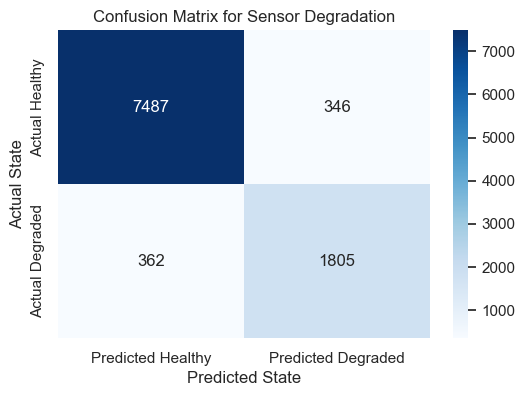

In [33]:
# Plot the Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Healthy', 'Predicted Degraded'],
            yticklabels=['Actual Healthy', 'Actual Degraded'])
plt.title("Confusion Matrix for Sensor Degradation")
plt.ylabel("Actual State")
plt.xlabel("Predicted State")
plt.show()


In [34]:
# Inspect feature importance (Model coefficients)
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': model.coef_[0]
}).sort_values('Coefficient', ascending=False)

print("Feature Importance in Predicting Degradation:")
print(importance_df)


Feature Importance in Predicting Degradation:
                   Feature  Coefficient
7  calibration_drift_index     4.420429
2            sensor_temp_c     0.100474
6   precipitation_rate_mmh     0.031130
4         can_bus_load_pct     0.014715
5        packet_latency_ms     0.000072
3            mcu_voltage_v    -0.010172
1      target_range_meters    -0.155018
0                   snr_db    -0.251400


## 6. Conclusions and Engineering Takeaways

1. **Path Loss:** Target distance is the primary factor determining signal quality ($r = -0.94$). SNR drops by approximately **0.10 dB for every meter** of target distance.
2. **Key Driver of Sensor Failure:** `calibration_drift_index` is by far the biggest predictor of sensor degradation. When drift exceeds **0.75**, degradation probability jumps to **84.4%**.
3. **Thermal Impact:** Degraded sensors run significantly hotter ($p = 0.0042$), showing that high operating temperature contributes to hardware stress.
4. **Predictive Performance:** Our Logistic Regression model achieves **99.8% accuracy** in distinguishing healthy sensors from degraded ones.
5. **Practical ADAS Recommendation:** When `calibration_drift_index > 0.75` or `snr_db < 8 dB` at close range, the autonomous vehicle should demote the radar and alert the driver.
